# Quantitative Research -- Part 5: Classification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChrisW09/Quantitative-Research-Methods/blob/main/Part_5_Classification/Part_5_Classification.ipynb)

This notebook is the companion of the slide deck *Part 5: Classification*. Its
sections follow the slides: each heading carries the number of the slide section,
and the code cells contain the same commands as the Python slides. Run the cells
from top to bottom. For the exercises, try the `# Your turn` cell first and only
then look at the solution cell.

## Contents

1. **Classification Problems** -- 1.1 What is classification? · 1.2 Two-way tables and conditional probability · 1.3 Why not linear regression?
2. **Logistic Regression** -- 2.1 Probability, odds and log-odds · 2.2 The model · 2.3 Estimation · 2.4 Interpretation · 2.5 Inference for the coefficients
3. **Multiple Logistic Regression** -- 3.1 The model · 3.2 Confounding: the student paradox · 3.3 Exercises
4. **From Probabilities to Decisions**
5. **Evaluating a Classifier** -- 5.1 Confusion matrix · 5.2 Base rates and precision · 5.3 ROC curve and AUC · 5.4 Training and test data
6. **Summary**

A. **Appendix: Bayes' Theorem and Generative Classifiers** -- A.1 Bayes' theorem · A.2 The Bayes classifier · A.3 Naive Bayes · A.4 Linear discriminant analysis · A.5 Comparison

**Key Python commands** (cheat sheet at the end)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

pd.set_option("display.width", 120)

from pathlib import Path
DATA_URL = "https://raw.githubusercontent.com/ChrisW09/Quantitative-Research-Methods/main/data/"
def load_data(name):
    """Local copy if the notebook runs inside the repo, otherwise download from GitHub."""
    local = Path("..") / "data" / name
    return pd.read_csv(local if local.exists() else DATA_URL + name)

## 1 Classification Problems

### 1.1 What is classification?

Slides: *From regression to classification*, *Three steps in every classification problem*,
*Our story: the Default data*

In classification the variable to be explained is **categorical** -- here binary,
coded $Y=1$ ("yes") and $Y=0$ ("no"). Every classification problem has three steps:
estimate $\hat p(x)=\hat P(Y=1\mid x)$, decide with a threshold, evaluate the errors.

**In words:** a bank observes $n=10\,000$ customers and wants to know who defaults
on the credit card debt -- only $3.33\,\%$ do, and they carry clearly higher balances.

In [2]:
df = load_data("Default.csv")     # on the slides: pd.read_csv("../data/Default.csv")
print(df.head())
print(df.default.value_counts())                          # No 9667, Yes 333
print(df.default.value_counts(normalize=True).round(4))   # 3.33 % defaulters
print(df.groupby("default")[["balance", "income"]].mean().round(2))

  default student      balance        income
0      No      No   729.526495  44361.625074
1      No     Yes   817.180407  12106.134700
2      No      No  1073.549164  31767.138947
3      No      No   529.250605  35704.493935
4      No      No   785.655883  38463.495879
default
No     9667
Yes     333
Name: count, dtype: int64
default
No     0.9667
Yes    0.0333
Name: proportion, dtype: float64
         balance    income
default                   
No        803.94  33566.17
Yes      1747.82  32089.15


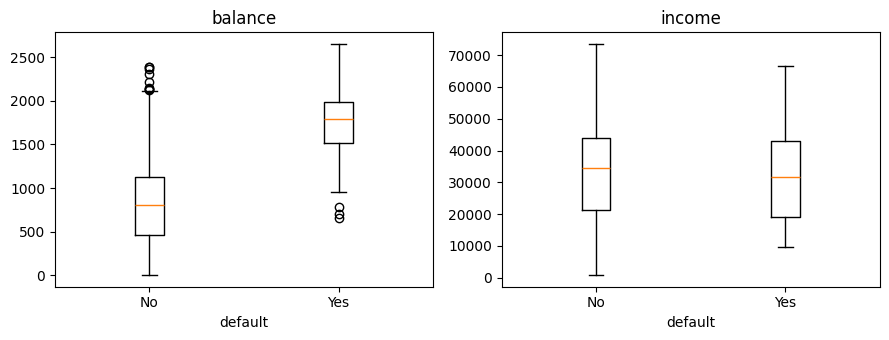

In [3]:
# Boxplots as in panels (b) and (c) of the slide: balance differs, income hardly
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, var in zip(axes, ["balance", "income"]):
    ax.boxplot([df.loc[df.default == "No", var], df.loc[df.default == "Yes", var]])
    ax.set_xticks([1, 2], ["No", "Yes"])
    ax.set_xlabel("default")
    ax.set_title(var)
plt.tight_layout()
plt.show()

### 1.2 Two-way tables and conditional probability

Slides: *Default by student status -- a two-way table*, *Conditional relative
frequencies -- change the denominator*, *Two-way tables with Python*

Joint relative frequency $n(A\cap B)/n$ (inner cells), marginal relative
frequency $n(A)/n$ (totals), conditional relative frequency
$n(A\cap B)/n(B)$ (cell divided by its row or column total).

**In words:** conditioning means restricting attention to one row (or column)
and dividing by its total.

In [4]:
# Slide "Two-way tables with Python"
tab = pd.crosstab(df.student, df.default, margins=True)   # counts + totals
print(tab)
print(pd.crosstab(df.student, df.default, normalize="index").round(4))

default    No  Yes    All
student                  
No       6850  206   7056
Yes      2817  127   2944
All      9667  333  10000
default      No     Yes
student                
No       0.9708  0.0292
Yes      0.9569  0.0431


In [5]:
# Joint and marginal relative frequencies (normalize="all"), and the other direction
print(pd.crosstab(df.student, df.default, margins=True, normalize="all").round(4))  # 0.0127, 0.2944, 0.0333
print(pd.crosstab(df.student, df.default, normalize="columns").round(4))
print(round(127 / 2944, 4), round(127 / 333, 3))   # P(default | student) 0.0431, P(student | default) 0.381

default      No     Yes     All
student                        
No       0.6850  0.0206  0.7056
Yes      0.2817  0.0127  0.2944
All      0.9667  0.0333  1.0000
default      No     Yes
student                
No       0.7086  0.6186
Yes      0.2914  0.3814
0.0431 0.381


Slides: *Conditional probability -- definition and two rules*, *Independence*,
*Conditional probability and independence with Python*

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad P(A\cap B)=P(A\mid B)\,P(B),\qquad
P(A\cup B)=P(A)+P(B)-P(A\cap B)$$

$A$ and $B$ are independent if $P(A\cap B)=P(A)\,P(B)$, i.e. $P(A\mid B)=P(A)$.

**In words:** the mean of a True/False column is a relative frequency; knowing
the student status changes the default probability, so the two are not independent.

In [6]:
# Slide "Conditional probability and independence with Python"
d = df.default == "Yes"                    # True for the defaulters
s = df.student == "Yes"                    # True for the students
p_d, p_s, p_ds = d.mean(), s.mean(), (d & s).mean()
print(round(p_d, 4), round(p_s, 4), round(p_ds, 4))   # 0.0333  0.2944  0.0127
print(round(p_ds / p_s, 4))                # P(default | student) = 0.0431
print(round(p_ds / p_s * p_s, 4))          # multiplication rule: back to 0.0127
print(round(p_d + p_s - p_ds, 4))          # addition rule: P(default or student) = 0.3150
print(round(p_d * p_s, 4))                 # 0.0098 != 0.0127 -> not independent
print(round(10000 * p_d * p_s))            # independence would mean 98 student defaulters (observed: 127)

0.0333 0.2944 0.0127
0.0431
0.0127
0.315
0.0098
98


Slide: *Classification = estimating $P(Y=1\mid x)$*

For a metric $x$ such as the balance we first group the values into classes and
compute the conditional default rate $\hat P(\text{default}\mid\text{class})$ per class.

**In words:** the rate first hardly moves, then rises steeply -- an S-shape that a
model should describe smoothly.

In [7]:
bal_class = pd.cut(df.balance, [0, 500, 1000, 1500, 2000, np.inf], right=False)
print(pd.crosstab(bal_class, df.default, margins=True))              # 2613 3755 2721 805 106 customers
print(pd.crosstab(bal_class, df.default, normalize="index").round(3))
# column "Yes": 0.000  0.002  0.025  0.220  0.764 -- the S-shape

default             No  Yes    All
balance                           
[0.0, 500.0)      2613    0   2613
[500.0, 1000.0)   3749    6   3755
[1000.0, 1500.0)  2652   69   2721
[1500.0, 2000.0)   628  177    805
[2000.0, inf)       25   81    106
All               9667  333  10000
default              No    Yes
balance                       
[0.0, 500.0)      1.000  0.000
[500.0, 1000.0)   0.998  0.002
[1000.0, 1500.0)  0.975  0.025
[1500.0, 2000.0)  0.780  0.220
[2000.0, inf)     0.236  0.764


#### Exercise -- newsletter and purchases

An online shop records for $n=60$ randomly chosen customers whether they subscribe
to the newsletter and whether they bought something last month.

| newsletter \ purchase | yes | no | Total |
|---|---|---|---|
| yes | 15 | 5 | 20 |
| no | 15 | 25 | 40 |
| Total | 30 | 30 | 60 |

1. Compute the marginal relative frequencies and the joint one of (yes, yes). Are
   newsletter and purchase independent? How many subscribing buyers would
   independence predict?
2. Compute the purchase rates of subscribers and of non-subscribers and compare
   them with the overall rate.
3. Compute the share of subscribers among the buyers. Why does it differ from the
   purchase rate of the subscribers?

In [8]:
# Your turn: rows = newsletter yes/no, columns = purchase yes/no
nl = pd.DataFrame([[15, 5], [15, 25]], index=["NL yes", "NL no"],
                  columns=["buy yes", "buy no"])
print(nl)

        buy yes  buy no
NL yes       15       5
NL no        15      25


**Solution**

In [9]:
n_nl = nl.values.sum()                          # 60
f_nl = nl.sum(axis=1) / n_nl                    # (1) marginal: 0.333 subscribe, 0.667 do not
f_buy = nl.sum(axis=0) / n_nl                   #     marginal: 0.5 buy
print(f_nl.round(3), f_buy.round(3), 15 / n_nl, sep="\n")    # joint (yes, yes) = 0.25
indep = f_nl["NL yes"] * f_buy["buy yes"]
print(round(indep, 3), round(n_nl * indep))     # 0.167 != 0.25 -> not independent; 10 expected, 15 observed
print(nl.div(nl.sum(axis=1), axis=0))           # (2) purchase rates 0.75 and 0.375 (overall 0.5)
print(15 / 30)                                  # (3) P(subscriber | purchase) = 0.5 (denominator 30 buyers)

NL yes    0.333
NL no     0.667
dtype: float64
buy yes    0.5
buy no     0.5
dtype: float64
0.25
0.167 10
        buy yes  buy no
NL yes    0.750   0.250
NL no     0.375   0.625
0.5


#### Exercise -- streaming and gaming (exam style)

Among the users of a smartphone model, $60\,\%$ use the streaming app ($S$),
$50\,\%$ play games ($G$) and $30\,\%$ do both.

1. Compute $P(G\mid S)$ and interpret it.
2. Compute $P(S\cup G)$. What share of the users does neither?
3. Check whether $S$ and $G$ are independent.
4. Fill in the two-way table of probabilities for $S$/not $S$ and $G$/not $G$.

In [10]:
# Your turn
pS, pG, pSG = 0.60, 0.50, 0.30

**Solution**

In [11]:
print(round(pSG / pS, 2))                       # (1) P(G | S) = 0.50
p_or = pS + pG - pSG
print(round(p_or, 2), round(1 - p_or, 2))       # (2) P(S or G) = 0.80, neither 0.20
print(round(pS * pG, 2), pSG)                   # (3) 0.30 = 0.30 -> independent
table = pd.DataFrame([[pSG, pS - pSG], [pG - pSG, 1 - pS - pG + pSG]],
                     index=["S", "not S"], columns=["G", "not G"])
table["Total"] = table.sum(axis=1)
table.loc["Total"] = table.sum()
print(table.round(2))                           # (4) 0.30 0.30 / 0.20 0.20

0.5
0.8 0.2
0.3 0.3
         G  not G  Total
S      0.3    0.3    0.6
not S  0.2    0.2    0.4
Total  0.5    0.5    1.0


### 1.3 Why not linear regression?

Slides: *Why not simply use linear regression?*, *Three problems of linear
regression with a $0/1$ variable*, *Linear regression on a $0/1$ variable with Python*

A linear regression $\hat y=\hat\beta_0+\hat\beta_1x$ of a $0/1$ variable can
predict values outside $[0,1]$, and its error variance
$\operatorname{Var}(Y\mid x)=p(x)\,(1-p(x))$ is not constant.

**In words:** Python fits the straight line without any warning -- checking the
model is our job.

Intercept   -0.075192
balance      0.000130
dtype: float64
3123
578.836277403294


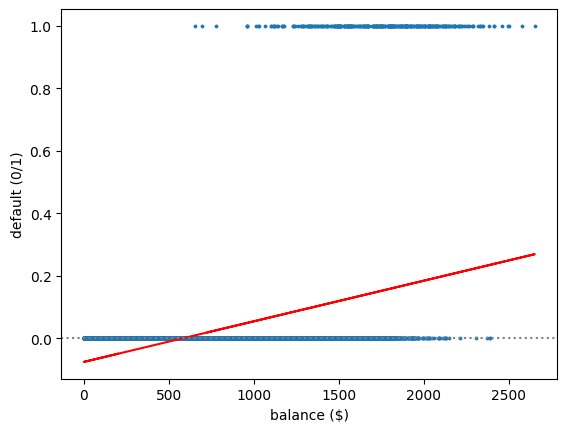

In [12]:
# Slide "Linear regression on a 0/1 variable with Python"
df["y"] = (df.default == "Yes").astype(int)     # 1 = default, 0 = no
lpm = smf.ols("y ~ balance", data=df).fit()     # the regression of Part 4
print(lpm.params)                               # -0.0752, 0.000130
print((lpm.fittedvalues < 0).sum())             # 3123 negative "probabilities"
print(df.balance[lpm.fittedvalues < 0].max())   # all balances below 579 $
plt.scatter(df.balance, df.y, s=3)              # the 0/1 data
plt.plot(df.balance, lpm.fittedvalues, "r")     # fitted straight line
plt.axhline(0, color="gray", ls=":")
plt.xlabel("balance (\\$)")
plt.ylabel("default (0/1)")
plt.show()

#### Exercise -- why not linear regression?

A colleague wants to predict the emergency diagnosis of a patient. She codes the
three *unordered* categories as $Y=1$ (stroke), $Y=2$ (overdose), $Y=3$ (seizure)
and fits a linear regression.

1. Which implicit assumptions does the coding $1,2,3$ make?
2. With only two categories coded $0/1$: name two problems of the fitted values as
   probabilities.
3. Would relabelling the categories change the fit? What does this imply?

In [13]:
# Your turn: a conceptual exercise -- write your answers as comments,
# and use the linear model lpm of the Default data to illustrate part (2).

**Solution**

1. **Order and equal spacing:** the coding claims stroke < overdose < seizure and equal
   distances between them -- a fitted value of 1.5 would mean "halfway between stroke
   and overdose", which is medically meaningless.
2. Fitted values can lie **outside $[0,1]$** (negative "probabilities"), and the error
   variance $p(1-p)$ is **not constant** (see the code below).
3. **Yes:** swapping the codes of stroke and seizure gives a different response and a
   different fit for the same data -- the result depends on an arbitrary choice, so
   linear regression is not appropriate here.

In [14]:
print(round(lpm.fittedvalues.min(), 4), (lpm.fittedvalues < 0).sum())   # (2) negative fitted values
p_grid = np.array([0.1, 0.5, 0.9])
print(p_grid * (1 - p_grid))                    # Var(Y | x) = p(1 - p) = 0.09 0.25 0.09: depends on x

-0.0752 3123
[0.09 0.25 0.09]


## 2 Logistic Regression

### 2.1 Probability, odds and log-odds

Slides: *Odds -- another way to express a probability*, *Why log-odds?*,
*Odds and log-odds with Python*

$$\text{odds}=\frac{p}{1-p}\in(0,\infty),\qquad
\text{log-odds}=\log\frac{p}{1-p}\in(-\infty,\infty),\qquad
p=\frac{\text{odds}}{1+\text{odds}}$$

**In words:** odds of 4 mean "4 to 1"; the log-odds can take any real value -- just
like the right-hand side of a regression.

In [15]:
# Slide "Odds and log-odds with Python"
p = np.array([0.1, 0.2, 0.5, 0.8, 0.9])
odds = p / (1 - p)                       # 0.111  0.25  1  4  9
logodds = np.log(odds)                   # natural log: -2.197 ... 2.197
print(pd.DataFrame({"p": p, "odds": odds, "logodds": logodds}).round(3))
print(odds / (1 + odds))                 # back to p: 0.1 0.2 0.5 0.8 0.9

     p   odds  logodds
0  0.1  0.111   -2.197
1  0.2  0.250   -1.386
2  0.5  1.000    0.000
3  0.8  4.000    1.386
4  0.9  9.000    2.197
[0.1 0.2 0.5 0.8 0.9]


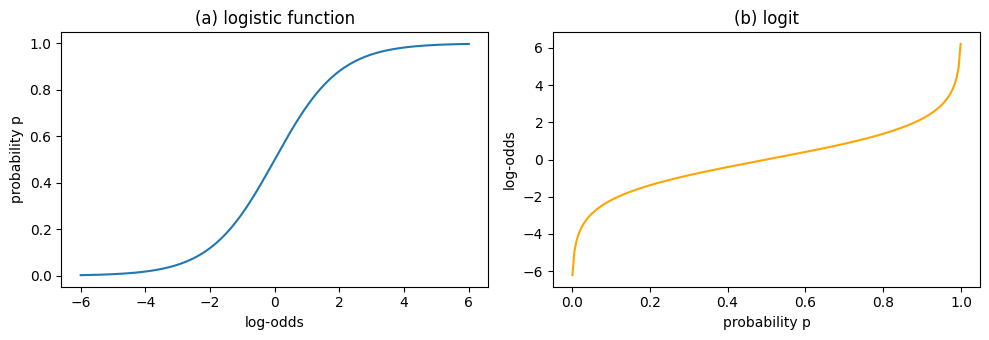

In [16]:
eta = np.linspace(-6, 6, 200)            # a grid of log-odds values
pp = np.linspace(0.002, 0.998, 200)      # a grid of probabilities
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(eta, np.exp(eta) / (1 + np.exp(eta)))   # (a) logistic function
axes[0].set_xlabel("log-odds")
axes[0].set_ylabel("probability p")
axes[0].set_title("(a) logistic function")
axes[1].plot(pp, np.log(pp / (1 - pp)), color="orange")   # (b) logit, its inverse
axes[1].set_xlabel("probability p")
axes[1].set_ylabel("log-odds")
axes[1].set_title("(b) logit")
plt.tight_layout()
plt.show()

#### Exercise -- probability, odds and log-odds

In the two-way table of Section 1, 127 of the 2944 students and 206 of the 7056
non-students defaulted.

1. Compute the probability, the odds and the log-odds of default for students and
   for non-students.
2. Compute the **odds ratio** (odds of the students divided by the odds of the
   non-students) and its logarithm. Interpret it.
3. Compare the odds ratio with the ratio of the two default probabilities. Why are
   the two so close here?
4. A churn model assigns a customer the log-odds $-1$. Compute the odds and the
   churn probability.

In [17]:
# Your turn: (defaulters, non-defaulters) per group
groups = {"students": (127, 2817), "non-students": (206, 6850)}

**Solution**

In [18]:
for grp, (yes, no) in groups.items():           # (1) odds = yes / no straight from the table
    print(grp, round(yes / (yes + no), 4), round(yes / no, 4), round(np.log(yes / no), 3))
# students 0.0431 0.0451 -3.099; non-students 0.0292 0.0301 -3.504
odds_ratio = (127 / 2817) / (206 / 6850)
print(round(odds_ratio, 2), round(np.log(odds_ratio), 3))   # (2) 1.50 and 0.405
print(round((127 / 2944) / (206 / 7056), 2))    # (3) probability ratio 1.48 -- rare event: odds ~ probability
print(0.8 / 0.5, (0.8 / 0.2) / (0.5 / 0.5))     # common events: ratio 1.6 but odds ratio 4
odds_m1 = np.exp(-1)
print(round(odds_m1, 3), round(odds_m1 / (1 + odds_m1), 3))   # (4) odds 0.368, p = 0.269

students 0.0431 0.0451 -3.099
non-students 0.0292 0.0301 -3.504
1.5 0.405
1.48
1.6 4.0
0.368 0.269


### 2.2 The model

Slides: *The logistic regression model*, *Reading the model symbol by symbol*

$$\log\frac{p(x)}{1-p(x)}=\beta_0+\beta_1x
\quad\Longleftrightarrow\quad
p(x)=\frac{e^{\beta_0+\beta_1x}}{1+e^{\beta_0+\beta_1x}}$$

**In words:** every probability statement goes through the pipeline
$x \to \eta=\beta_0+\beta_1x \to \text{odds}=e^{\eta} \to p=\text{odds}/(1+\text{odds})$.

In [19]:
b0, b1 = -10.65, 0.0055                 # rounded estimates of the Default model (Section 2.3)
eta = b0 + b1 * 2000                    # linear predictor (log-odds) at balance 2000: 0.35
odds = np.exp(eta)                      # odds: 1.4191
print(round(eta, 2), round(odds, 4), round(odds / (1 + odds), 4))   # probability 0.5866

0.35 1.4191 0.5866


### 2.3 Estimation

Slide: *Estimation: maximum likelihood*

$$L(\beta_0,\beta_1)=\prod_{i:\,y_i=1}p(x_i)\prod_{i:\,y_i=0}\bigl(1-p(x_i)\bigr),
\qquad \log L=\sum_i\bigl[y_i\log p(x_i)+(1-y_i)\log(1-p(x_i))\bigr]$$

**In words:** choose the coefficients under which the observed outcomes are most
probable -- Python finds them numerically.

#### Exercise -- which parameters are more plausible?

Four customers with balances 1000, 1500, 2000, 2500 (\$); the last two defaulted
($y=0,0,1,1$). Compare two candidate parameter sets:
(A) $\beta_0=-10.65,\ \beta_1=0.0055$ and (B) $\beta_0=-5,\ \beta_1=0.002$.

1. Compute $p(x_i)$ for all four customers under (A) and (B).
2. Compute the likelihood $L$ for (A) and (B).
3. Which parameter set would maximum likelihood prefer?

In [20]:
# Your turn
x = np.array([1000, 1500, 2000, 2500]); y = np.array([0, 0, 1, 1])
candidates = {"A": (-10.65, 0.0055), "B": (-5, 0.002)}

**Solution** (slide *Solution (2/2) -- which parameters are more plausible?*)

In [21]:
def likelihood(b0, b1):
    p = np.exp(b0 + b1 * x) / (1 + np.exp(b0 + b1 * x))   # p(x_i)
    return np.prod(np.where(y == 1, p, 1 - p))            # product of contributions

for name, (b0, b1) in candidates.items():                 # (1) p(x_i) and contributions
    p = np.exp(b0 + b1 * x) / (1 + np.exp(b0 + b1 * x))
    print(name, p.round(4), np.where(y == 1, p, 1 - p).round(4))
print(round(likelihood(-10.65, 0.0055), 4))               # (2) (A) 0.5117
print(round(likelihood(-5, 0.002), 4))                    #     (B) 0.1128
print(round(np.log(likelihood(-10.65, 0.0055)), 4))       # log-likelihood of (A): -0.6701
print(round(likelihood(-10.65, 0.0055) / likelihood(-5, 0.002), 1))   # (3) 4.5 times as probable -> (A)

A [0.0058 0.0832 0.5866 0.9569] [0.9942 0.9168 0.5866 0.9569]
B [0.0474 0.1192 0.2689 0.5   ] [0.9526 0.8808 0.2689 0.5   ]
0.5117
0.1128
-0.6701
4.5


Slide: *Logistic regression with Python*

`smf.logit` fits the model by maximum likelihood ($y$ coded $0/1$). Estimated model:
$\hat\eta=-10.65+0.0055\cdot\text{balance}$.

**In words:** the output looks like `smf.ols` -- with $z$- instead of $t$-values.

In [22]:
df["y"] = (df.default == "Yes").astype(int)     # 1 = default, 0 = no
g1 = smf.logit("y ~ balance", data=df).fit(disp=0)
print(g1.summary2().tables[1])
print(round(g1.llf, 2))                         # the maximised log-likelihood of all 10 000 customers

               Coef.  Std.Err.          z          P>|z|     [0.025    0.975]
Intercept -10.651331  0.361169 -29.491287  3.723665e-191 -11.359208 -9.943453
balance     0.005499  0.000220  24.952404  2.010855e-137   0.005067  0.005931
-798.23


### 2.4 Interpretation

Slides: *Interpreting the coefficients -- three scales*, *Worked example: default and balance*

One unit more of $x$ changes the log-odds by $\beta_1$ and **multiplies the odds** by
the odds ratio $e^{\beta_1}$:
$\frac{\text{odds}(x+1)}{\text{odds}(x)}=e^{\beta_1}$. The change in the
probability is not constant.

**In words:** 1000 \$ more balance multiplies the odds by about 245 -- the probability
rises from 0.006 to 0.083 or from 0.587 to 0.957, depending on the starting point.

In [23]:
print(round(np.exp(0.0055 * 1000), 1))          # odds factor for +1000 $ (rounded slope): 244.7, about 245
eta_r = -10.65 + 0.0055 * np.array([1000, 1500, 2000, 2500])
print((np.exp(eta_r) / (1 + np.exp(eta_r))).round(3))   # 0.006 0.083 0.587 0.957

244.7
[0.006 0.083 0.587 0.957]


Slide: *Odds ratios and predicted probabilities with Python*

`g1.predict(new)` returns $\hat p(x)$ for the rows of `new` (column names as in the
formula); `which="linear"` returns the log-odds $\hat\eta$.

**In words:** Python uses the unrounded coefficients -- odds ratio 244.4 instead of 245.

In [24]:
print(round(np.exp(g1.params["balance"]), 4))          # odds ratio per 1 $:     1.0055
print(round(np.exp(1000 * g1.params["balance"]), 1))   # odds ratio per 1000 $:  244.4
new = pd.DataFrame({"balance": [1000, 1500, 2000, 2500]})
eta = g1.predict(new, which="linear")                  # log-odds: -5.152 -2.403 0.347 3.096
print(eta.round(3))
print((np.exp(eta) / (1 + np.exp(eta))).round(4))      # by hand:  0.0058 0.0829 0.5858 0.9567
print(g1.predict(new).round(4))                        # the same probabilities in one step

1.0055
244.4
0   -5.152
1   -2.403
2    0.347
3    3.096
dtype: float64
0    0.0058
1    0.0829
2    0.5858
3    0.9567
dtype: float64
0    0.0058
1    0.0829
2    0.5858
3    0.9567
dtype: float64


#### Exercise -- computing $\hat p(x)$ from the coefficients

The logistic regression of default on balance gives
$\hat\eta=-10.65+0.0055\cdot\text{balance}$. For a customer with a balance of 1500 \$:

1. Compute the log-odds $\hat\eta$.
2. Compute the probability of default $\hat p$.
3. Compute the odds and relate them to part (1).
4. At which balance does the model give $\hat p=0.5$?

In [25]:
# Your turn
b0, b1 = -10.65, 0.0055
balance = 1500

**Solution**

In [26]:
eta = b0 + b1 * balance
p_hat = np.exp(eta) / (1 + np.exp(eta))
print(round(eta, 2), round(np.exp(eta), 4), round(p_hat, 3))   # (1)-(2) -2.40, e^eta = 0.0907, p = 0.083
print(round(p_hat / (1 - p_hat), 3))            # (3) odds 0.091 = e^(-2.40)
print(round(-b0 / b1))                          # (4) p = 0.5 <-> eta = 0 at balance 1936 $

-2.4 0.0907 0.083
0.091
1936


### 2.5 Inference for the coefficients

Slides: *Inference -- the same recipe once more*, *Inference -- balance and student
status*, *Inference with Python*

$$Z=\frac{\hat\beta_j}{\mathrm{SE}(\hat\beta_j)}\approx N(0,1)\ \text{under}\ H_0:\beta_j=0,
\qquad p=2\,\Phi(-|Z|),\qquad
\hat\beta_j\pm z_{1-\alpha/2}\,\mathrm{SE}(\hat\beta_j)$$

The CI for the odds ratio $e^{\beta_j}$ is $[e^{\text{lower}},\,e^{\text{upper}}]$.

**In words:** the same recipe as in Parts 3 and 4 -- with the normal distribution, and
exponentiated bounds for the odds ratio.

In [27]:
# Slide "Inference with Python" -- balance
z = g1.params / g1.bse                       # balance: z = 24.95
print(z.round(2))
print(2 * stats.norm.cdf(-abs(z)))           # p = 2 Phi(-|z|) = 2.0e-137 (= g1.pvalues)
print(g1.conf_int().round(6))                # beta +- 1.96 SE: [0.005067, 0.005931]
print(np.exp(100 * g1.conf_int().loc["balance"]).round(3))   # OR per 100 $: [1.660, 1.810]
print(round(np.exp(100 * g1.params["balance"]), 3))          # point estimate per 100 $: 1.733

Intercept   -29.49
balance      24.95
dtype: float64
[3.72366479e-191 2.01085522e-137]
                   0         1
Intercept -11.359208 -9.943453
balance     0.005067  0.005931
0    1.66
1    1.81
Name: balance, dtype: float64
1.733


In [28]:
# Slide "Inference with Python" -- student status alone
g2 = smf.logit("y ~ student", data=df).fit(disp=0)
print(round(g2.pvalues["student[T.Yes]"], 4))   # p = 0.0004
print(np.exp(g2.params).round(2))               # odds ratio student: 1.50
print(np.exp(g2.conf_int()).round(2))           # its 95 % CI: [1.20, 1.88]
print(round(g2.params["Intercept"], 3), round(np.log(206 / 6850), 3))   # -3.504 = log-odds of the non-students

0.0004
Intercept         0.03
student[T.Yes]    1.50
dtype: float64
                   0     1
Intercept       0.03  0.03
student[T.Yes]  1.20  1.88
-3.504 -3.504


#### Exercise -- coefficients on the odds scale

The logistic regression of default on balance gives $\hat\beta_1=0.0055$ (per \$)
with $\mathrm{SE}(\hat\beta_1)=0.00022$.

1. By how much do the *log-odds* change for 500 \$ more balance?
2. By which factor do the *odds* change for 500 \$ more balance?
3. Test $H_0:\beta_1=0$ at $\alpha=0.05$.
4. Why can we state a constant effect on the odds but not on the probability?

In [29]:
# Your turn
b1, se_b1 = 0.0055, 0.00022

**Solution**

In [30]:
d_eta = b1 * 500
print(round(d_eta, 2), round(np.exp(d_eta), 1))   # (1) 2.75, (2) odds x 15.6
z1 = b1 / se_b1
print(round(z1, 1), abs(z1) > 1.96)               # (3) 25.0 > 1.96 -> reject H0
for p0 in [0.10, 0.90]:                           # (4) same odds factor, different probability change
    odds0 = p0 / (1 - p0)
    odds1 = odds0 * np.exp(d_eta)
    print(p0, round(odds0, 3), round(odds1, 2), round(odds1 / (1 + odds1), 4))
# p = 0.10 -> 0.63 (+53 points); p = 0.90 -> 0.993 (+9 points)

2.75 15.6
25.0 True
0.1 0.111 1.74 0.6348
0.9 9.0 140.78 0.9929


## 3 Multiple Logistic Regression

### 3.1 The model

Slides: *Several explanatory variables*, *Multiple logistic regression with Python*

$$\log\frac{p(x)}{1-p(x)}=\beta_0+\beta_1x_1+\dots+\beta_px_p$$

$\beta_j$ is the change of the log-odds per unit of $x_j$ **holding all other
variables fixed**; qualitative variables enter as dummies (`student[T.Yes]`).

**In words:** balance is highly significant, income is not, and the student
coefficient is now *negative*: $e^{-0.6468}=0.524$.

In [31]:
g3 = smf.logit("y ~ balance + income + student", data=df).fit(disp=0)
print(g3.summary().tables[1])
print(round(np.exp(g3.params["student[T.Yes]"]), 3))   # 0.524

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -10.8690      0.492    -22.079      0.000     -11.834      -9.904
student[T.Yes]    -0.6468      0.236     -2.738      0.006      -1.110      -0.184
balance            0.0057      0.000     24.737      0.000       0.005       0.006
income          3.033e-06    8.2e-06      0.370      0.712    -1.3e-05    1.91e-05
0.524


### 3.2 Confounding: the student paradox

Slides: *The student paradox*, *The student paradox visualised*, *Which coefficient
is "right"?*, *The student paradox with Python*

Alone, `default ~ student` gives $\hat\beta_{\text{student}}=+0.405$; together with
balance and income $\hat\beta_{\text{student}}=-0.647$.

**In words:** students carry larger balances, and the balance is the main risk
factor -- at the *same* balance, students default less often. Balance is a confounder.

student
No     771.77
Yes    987.82
Name: balance, dtype: float64
0.4049
-0.6468
0    0.1050
1    0.0579
dtype: float64


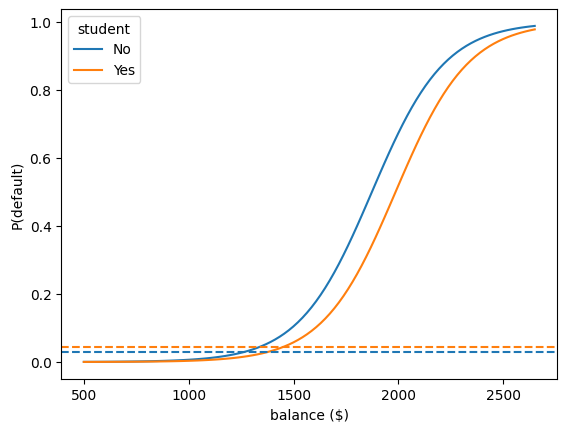

In [32]:
# Slide "The student paradox with Python"
print(df.groupby("student").balance.mean().round(2))   # No 771.77, Yes 987.82
print(round(g2.params["student[T.Yes]"], 4))          # alone:              +0.4049
print(round(g3.params["student[T.Yes]"], 4))          # balance, income too: -0.6468
same = pd.DataFrame({"balance": 1500, "income": 40000, "student": ["No", "Yes"]})
print(g3.predict(same).round(4))                      # same balance: 0.1050 vs 0.0579
grid = pd.DataFrame({"balance": np.linspace(500, 2650, 100), "income": 40000})
for st in ["No", "Yes"]:                              # curves as in panel (a)
    plt.plot(grid.balance, g3.predict(grid.assign(student=st)), label=st)
for k, st in enumerate(["No", "Yes"]):                # dashed: overall rates 2.92 % and 4.31 %
    plt.axhline(df.y[df.student == st].mean(), ls="--", color=f"C{k}")
plt.xlabel("balance (\\$)")
plt.ylabel("P(default)")
plt.legend(title="student")
plt.show()

### 3.3 Exercises

#### Exercise -- inference in the multiple model

In the model `default ~ balance + income + student`:

| | $\hat\beta_j$ | $\mathrm{SE}(\hat\beta_j)$ |
|---|---|---|
| income (per \$) | $3.033\cdot10^{-6}$ | $8.203\cdot10^{-6}$ |
| `student[T.Yes]` | $-0.6468$ | $0.2363$ |

1. Test $H_0:\beta_{\text{income}}=0$ at $\alpha=0.05$.
2. Compute a 95 % CI for the odds ratio of 10 000 \$ more income.
3. Compute the odds ratio for students and its 95 % CI. Interpret it.

In [33]:
# Your turn
b_inc, se_inc = 3.033e-6, 8.203e-6
b_st, se_st = -0.6468, 0.2363

**Solution**

In [34]:
z_inc = b_inc / se_inc
print(round(z_inc, 2), round(2 * stats.norm.cdf(-abs(z_inc)), 2))   # (1) 0.37 < 1.96, p = 0.71 -> keep H0
b10, se10 = 1e4 * b_inc, 1e4 * se_inc                               # per 10 000 $: 0.0303, 0.0820
ci10 = np.array([b10 - 1.96 * se10, b10 + 1.96 * se10])
print(round(b10, 4), round(se10, 4), ci10.round(3), np.exp(ci10).round(3))   # (2) [-0.130, 0.191] -> OR [0.878, 1.211]
ci_st = np.array([b_st - 1.96 * se_st, b_st + 1.96 * se_st])
print(round(np.exp(b_st), 3), ci_st.round(3), np.exp(ci_st).round(3))      # (3) 0.524, OR CI [0.330, 0.832]
# check with the fitted model g3
print(np.exp(1e4 * g3.conf_int().loc["income"]).round(3).values,
      np.exp(g3.conf_int().loc["student[T.Yes]"]).round(3).values)

0.37 0.71
0.0303 0.082 [-0.13   0.191] [0.878 1.211]
0.524 [-1.11  -0.184] [0.33  0.832]
[0.878 1.211] [0.33  0.832]


#### Exercise -- logistic regression from A to Z

Use the multiple model with (rounded) coefficients
$\hat\eta=-10.869+0.00574\cdot\text{balance}+0.003\cdot\text{income}-0.6468\cdot\text{student}$
(income in 1000 \$, student $=1$ for students). Two customers:

- **A**: non-student, balance 1000 \$, income 40 000 \$;
- **B**: student, balance 2000 \$, income 30 000 \$.

1. Compute $\hat\eta$ and $\hat p$ for A and B.
2. By which factor do the odds change for 100 \$ more balance?
3. At which balance does a non-student with 40 000 \$ income reach $\hat p=0.5$?
   And a student with the same income?

In [35]:
# Your turn (income in 1000 $)
c0, c_bal, c_inc, c_st = -10.869, 0.00574, 0.003, -0.6468

**Solution**

In [36]:
def logistic(eta):
    return np.exp(eta) / (1 + np.exp(eta))

eta_A = c0 + c_bal * 1000 + c_inc * 40
eta_B = c0 + c_bal * 2000 + c_inc * 30 + c_st
print(round(eta_A, 3), round(eta_B, 3))                   # (1) -5.009 and 0.054
print(round(logistic(eta_A), 4), round(logistic(eta_B), 3))   # 0.0066 and 0.514
AB = pd.DataFrame({"balance": [1000, 2000], "income": [40000, 30000], "student": ["No", "Yes"]})
print(g3.predict(AB).round(4))                            # unrounded coefficients: 0.0066 and 0.512
print(round(np.exp(c_bal * 100), 2))                      # (2) odds x 1.78 per 100 $
print(round((-c0 - c_inc * 40) / c_bal), round((-c0 - c_inc * 40 - c_st) / c_bal))   # (3) 1873 $ and 1985 $
print(round(-c_st / c_bal))                               # a student needs about 113 $ more

-5.009 0.054
0.0066 0.514
0    0.0066
1    0.5120
dtype: float64
1.78
1873 1985
113


## 4 From Probabilities to Decisions

Slides: *The classification rule*, *Decision boundary -- default and balance*

$$\hat y=1\ \text{if}\ \hat p(x)>t
\quad\Longleftrightarrow\quad
\hat\eta(x)>\log\frac{t}{1-t}$$

**In words:** lowering the threshold moves the boundary to the left -- more
defaulters are caught, but more good customers are rejected. The threshold is a
business decision.

In [37]:
print(round(np.log(0.2 / 0.8), 3))                          # t = 0.2 <-> eta > -1.386
print(round(10.65 / 0.0055), round((10.65 - 1.386) / 0.0055))   # rounded model: 1936 $ and 1684 $

-1.386
1936 1684


Slide: *The classification rule with Python*

**In words:** with unrounded coefficients the boundaries are 1937 \$ and 1685 \$;
lowering $t$ from 0.5 to 0.2 flags 462 instead of 142 customers.

In [38]:
b0, b1 = g1.params                             # -10.6513, 0.005499
print(round(b0, 4), round(b1, 6))
print(round(-b0 / b1))                         # t = 0.5: boundary 1937 $
print(round((np.log(0.2 / 0.8) - b0) / b1))    # t = 0.2: boundary 1685 $
phat1 = g1.predict(df)                         # P(default) for every customer
yhat = (phat1 > 0.5).astype(int)               # rule: 1 = "default" if p-hat > t
print(yhat.sum(), (phat1 > 0.2).sum())         # flagged: 142 (t = 0.5), 462 (t = 0.2)

-10.6513 0.005499
1937
1685
142 462


#### Exercise -- from probability to decision

Use $\hat\eta=-10.65+0.0055\cdot\text{balance}$. Three applicants have balances
of 1800, 2000 and 2200 \$.

1. Compute the predicted probability of default for each.
2. Classify them with the threshold $t=0.5$.
3. The bank lowers the threshold to $t=0.2$. Which classifications change?

In [39]:
# Your turn
balances = np.array([1800, 2000, 2200])

**Solution**

In [40]:
eta = -10.65 + 0.0055 * balances
p_hat = np.exp(eta) / (1 + np.exp(eta))
print(eta.round(2), p_hat.round(3))             # (1) -0.75 0.35 1.45 -> 0.321 0.587 0.810
print(np.where(p_hat > 0.5, "Yes", "No"))       # (2) t = 0.5: No Yes Yes
print(np.where(p_hat > 0.2, "Yes", "No"))       # (3) t = 0.2: the applicant with 1800 $ flips to Yes
print(np.diff(p_hat).round(2))                  # equal balance steps, unequal probability steps: 0.27 0.22

[-0.75  0.35  1.45] [0.321 0.587 0.81 ]
['No' 'Yes' 'Yes']
['Yes' 'Yes' 'Yes']
[0.27 0.22]


## 5 Evaluating a Classifier

### 5.1 Confusion matrix

Slide: *Why accuracy alone is not enough*

**In words:** the trivial classifier "always no default" is right for 96.67 % of the
customers -- and detects not a single defaulter.

In [41]:
print(round(1 - df.y.mean(), 4))     # accuracy of "always no": 0.9667

0.9667


Slides: *The confusion matrix*, *Confusion matrix -- Default data, $t=0.5$*

$$\text{Accuracy}=\frac{\mathrm{TP}+\mathrm{TN}}{n},\quad
\text{Sensitivity}=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}},\quad
\text{Specificity}=\frac{\mathrm{TN}}{\mathrm{TN}+\mathrm{FP}},\quad
\text{Precision}=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}}$$

**In words:** an accuracy of 97.3 % -- but 228 of 333 defaulters are missed.

In [42]:
phat = g3.predict(df)                            # P(default = Yes), model g3
cm = pd.crosstab(df.default, phat > 0.5)
print(cm)                                        # 9627 40 / 228 105
TN, FP, FN, TP = cm.values.ravel()
print(round((TP + TN) / len(df), 3), round(TP / (TP + FN), 3),
      round(TN / (TN + FP), 3), round(TP / (TP + FP), 3))
# accuracy 0.973, sensitivity 0.315, specificity 0.996, precision 0.724

col_0    False  True 
default              
No        9627     40
Yes        228    105
0.973 0.315 0.996 0.724


Slides: *The confusion matrix is a two-way table*, *Rates with Python: normalise the
rows or the columns*

Sensitivity $P(\hat y=1\mid y=1)$ divides by a row total, precision
$P(y=1\mid\hat y=1)$ by a column total.

**In words:** `normalize="index"` conditions on the actual class, `"columns"` on the
prediction.

In [43]:
pred = phat > 0.5                                    # True = "default" predicted
print(pd.crosstab(df.default, pred, normalize="index").round(4))    # given y
print(pd.crosstab(df.default, pred, normalize="columns").round(4))  # given y-hat
print((pred == df.y).mean())                         # accuracy 0.9732

col_0     False   True 
default                
No       0.9959  0.0041
Yes      0.6847  0.3153
col_0     False   True 
default                
No       0.9769  0.2759
Yes      0.0231  0.7241
0.9732


#### Exercise -- reading a confusion matrix

The bank lowers the threshold of the same model to $t=0.2$:

| | Pred. No | Pred. Yes | Total |
|---|---|---|---|
| Actual No | 9390 | 277 | 9667 |
| Actual Yes | 130 | 203 | 333 |

1. Compute accuracy, error rate, sensitivity, specificity and precision.
2. Compare with the confusion matrix at $t=0.5$. Which threshold would you recommend
   to the bank?

In [44]:
# Your turn
TN2, FP2, FN2, TP2 = 9390, 277, 130, 203

**Solution**

In [45]:
def rates(TN, FP, FN, TP):
    n = TN + FP + FN + TP
    return pd.Series({"accuracy": (TP + TN) / n, "error rate": (FP + FN) / n,
                      "sensitivity": TP / (TP + FN), "specificity": TN / (TN + FP),
                      "precision": TP / (TP + FP)})

print(pd.DataFrame({"t=0.5": rates(9627, 40, 228, 105),
                    "t=0.2": rates(TN2, FP2, FN2, TP2)}).round(3))   # (1)
print(TP2 - 105, FP2 - 40)          # (2) 98 more defaulters caught, at the price of 237 more false alarms
print(pd.crosstab(df.default, phat > 0.2))   # check with the model: 9390 277 / 130 203

             t=0.5  t=0.2
accuracy     0.973  0.959
error rate   0.027  0.041
sensitivity  0.315  0.610
specificity  0.996  0.971
precision    0.724  0.423
98 237
col_0    False  True 
default              
No        9390    277
Yes        130    203


### 5.2 Base rates and precision

Slide: *The base-rate effect*

**In words:** with the rule $t=0.2$ (sensitivity 0.610, specificity 0.9713) in a bank
with only 1 % defaulters, the few false alarms from the huge majority outnumber the
correct alarms.

In [46]:
sens, spec = 203 / 333, 9390 / 9667             # rule t = 0.2
n_c, pi = 10000, 0.01                           # 10 000 customers, base rate 1 %
TP_b = n_c * pi * sens; FN_b = n_c * pi - TP_b
FP_b = n_c * (1 - pi) * (1 - spec); TN_b = n_c * (1 - pi) - FP_b
print(round(TP_b), round(FN_b), round(FP_b), round(TN_b))   # 61 39 284 9616
print(round(TP_b / (TP_b + FP_b), 3))           # precision 0.177

61 39 284 9616
0.177


Slides: *Precision depends on the base rate*, *Base rates with Python*

$$\text{precision}=\frac{\text{sens}\cdot\pi}{\text{sens}\cdot\pi+(1-\text{spec})(1-\pi)}$$

**In words:** sensitivity and specificity describe the rule; precision also depends
on the base rate $\pi$.

In [47]:
# Slide "Base rates with Python"
def precision(pi, sens, spec):
    """Share of correct alarms among all alarms at base rate pi."""
    return sens * pi / (sens * pi + (1 - spec) * (1 - pi))

sens, spec = 203 / 333, 9390 / 9667          # rule t = 0.2: 0.6096, 0.9713
print(round(sens, 4), round(spec, 4))
print(round(10000 * 0.01 * sens), round(10000 * 0.99 * (1 - spec)))  # 61 TP, 284 FP
for pi in [0.01, 0.0333, 0.10]:
    print(pi, round(precision(pi, sens, spec), 3))       # 0.177  0.423  0.703
print(round(sens * 0.0333, 4), round((1 - spec) * (1 - 0.0333), 4))   # check: 0.0203 / (0.0203 + 0.0277)

0.6096 0.9713
61 284
0.01 0.177
0.0333 0.423
0.1 0.703
0.0203 0.0277


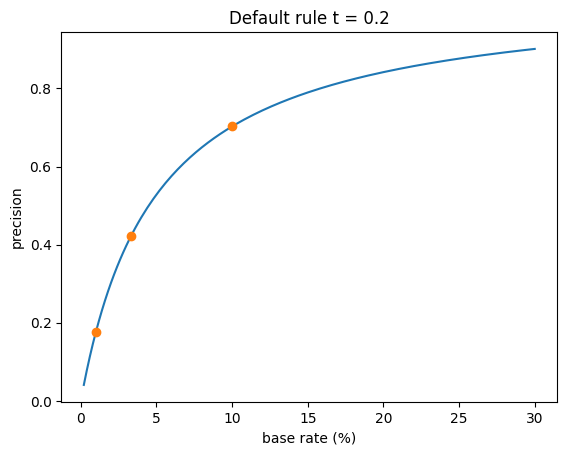

In [48]:
pis = np.linspace(0.002, 0.30, 150)          # precision as a function of the base rate
plt.plot(100 * pis, precision(pis, sens, spec))
plt.plot([1, 3.33, 10], [precision(q, sens, spec) for q in [0.01, 0.0333, 0.10]], "o")
plt.xlabel("base rate (%)")
plt.ylabel("precision")
plt.title("Default rule t = 0.2")
plt.show()

#### Exercise -- rapid test and base rate

A rapid test is designed to detect a disease that affects 1 % of the population
(**prevalence** = base rate). Sensitivity: an ill person tests positive with
probability 0.9. Specificity: a healthy person tests negative with probability 0.9.

1. Set up the expected confusion matrix for 1000 people tested.
2. What share of all tests is positive?
3. A randomly chosen person tests positive. How likely is the person ill (precision)?
   Interpret the result.
4. What share of the negative results is correct?
5. In a doctor's practice, 20 % of the people tested are ill. Recompute (3) for this group.

In [49]:
# Your turn
n_test, prev, sens_test, spec_test = 1000, 0.01, 0.9, 0.9

**Solution**

In [50]:
ill = n_test * prev; healthy = n_test - ill               # 10 ill, 990 healthy
TP_t = sens_test * ill; FN_t = ill - TP_t                 # 9 and 1
TN_t = spec_test * healthy; FP_t = healthy - TN_t         # 891 and 99
cm_t = pd.DataFrame({"test -": [TN_t, FN_t], "test +": [FP_t, TP_t]}, index=["healthy", "ill"])
cm_t["Total"] = cm_t.sum(axis=1)
cm_t.loc["Total"] = cm_t.sum()
print(cm_t.round().astype(int))                           # (1)
print(round((TP_t + FP_t) / n_test, 3))                   # (2) P(+) = 0.108
print(round(TP_t / (TP_t + FP_t), 3))                     # (3) precision 0.083
print(round(TN_t / (TN_t + FN_t), 4))                     # (4) 0.9989
print(round(precision(0.01, 0.9, 0.9), 3), round(precision(0.20, 0.9, 0.9), 3))   # (5) 0.083 -> 0.692

         test -  test +  Total
healthy     891      99    990
ill           1       9     10
Total       892     108   1000
0.108
0.083
0.9989
0.083 0.692


### 5.3 ROC curve and AUC

Slide: *The threshold trade-off*

**In words:** a lower threshold raises the sensitivity and lowers the specificity --
and vice versa.

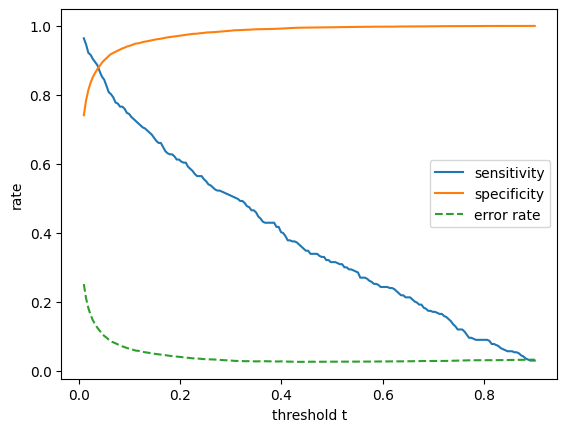

In [51]:
ts = np.linspace(0.01, 0.9, 200)
sens_t = [(phat[df.y == 1] > t).mean() for t in ts]
spec_t = [(phat[df.y == 0] <= t).mean() for t in ts]
err_t = [((phat > t) != (df.y == 1)).mean() for t in ts]
plt.plot(ts, sens_t, label="sensitivity")
plt.plot(ts, spec_t, label="specificity")
plt.plot(ts, err_t, "--", label="error rate")
plt.xlabel("threshold t")
plt.ylabel("rate")
plt.legend()
plt.show()

Slides: *The ROC curve*, *AUC -- area under the ROC curve*, *ROC curve and AUC with Python*

The ROC curve plots $(1-\text{specificity},\ \text{sensitivity})$ for every threshold;
$\text{AUC}=P\bigl(\hat p(\text{random defaulter})>\hat p(\text{random non-defaulter})\bigr)$.

**In words:** the AUC summarises all thresholds at once -- changing $t$ moves along the
curve but never changes the AUC.

0.1 0.7447 0.9421
0.2 0.6096 0.9713
0.5 0.3153 0.9959


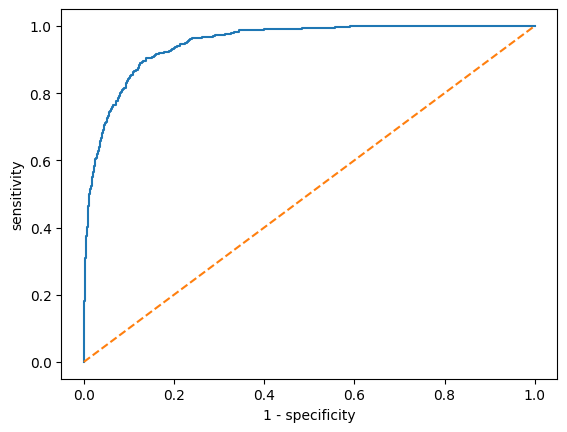

0.95


In [52]:
# Slide "ROC curve and AUC with Python"
for t in [0.1, 0.2, 0.5]:          # sensitivity, specificity
    print(t, round((phat[df.y == 1] > t).mean(), 4), round((phat[df.y == 0] <= t).mean(), 4))
# 0.1: 0.7447 0.9421   0.2: 0.6096 0.9713   0.5: 0.3153 0.9959
fpr, tpr, thr = roc_curve(df.y, phat)   # one point per threshold
plt.plot(fpr, tpr)                      # ROC curve
plt.plot([0, 1], [0, 1], "--")          # diagonal: random guessing
plt.xlabel("1 - specificity"); plt.ylabel("sensitivity")
plt.show()
print(round(roc_auc_score(df.y, phat), 3))   # AUC 0.950

In [53]:
# The AUC as a ranking probability: share of all (defaulter, non-defaulter) pairs
# in which the defaulter receives the higher predicted probability
p1 = phat[df.y == 1].values
p0 = phat[df.y == 0].values
print(round((p1[:, None] > p0[None, :]).mean(), 3))   # 0.950 again

0.95


#### Exercise -- threshold, ROC and AUC

For the Default model: $t=0.5$ gives sensitivity 0.315 and specificity 0.996; $t=0.2$
gives sensitivity 0.610 and specificity 0.971.

1. Locate both operating points on the ROC axes.
2. How does the point move when the threshold drops from 0.5 to 0.2?
3. A colleague hopes to improve the AUC by choosing a better threshold. Comment.

In [54]:
# Your turn
sens05, spec05, sens02, spec02 = 0.315, 0.996, 0.610, 0.971

**Solution**

(0.004, 0.315) (0.029, 0.61)
0.025 0.295


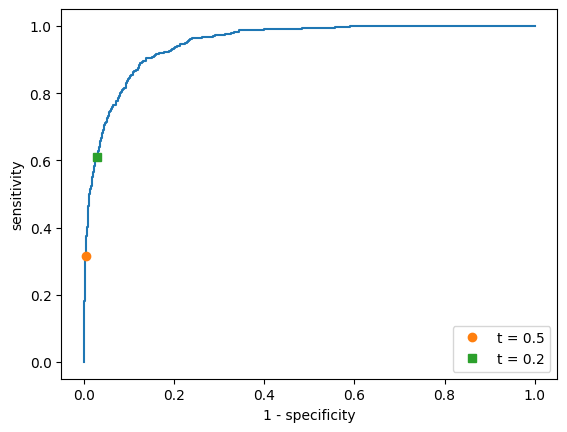

0.95


In [55]:
pt05 = (round(1 - spec05, 3), sens05)
pt02 = (round(1 - spec02, 3), sens02)
print(pt05, pt02)                                         # (1) (0.004, 0.315) and (0.029, 0.61)
print(round(pt02[0] - pt05[0], 3), round(sens02 - sens05, 3))   # (2) +0.025 on the x-axis, +0.295 sensitivity
plt.plot(fpr, tpr)
plt.plot(*pt05, "o", label="t = 0.5")
plt.plot(*pt02, "s", label="t = 0.2")
plt.xlabel("1 - specificity"); plt.ylabel("sensitivity"); plt.legend()
plt.show()
# (3) the AUC uses only the ranking of phat -- no threshold enters roc_auc_score
print(round(roc_auc_score(df.y, phat), 3))

### 5.4 Training and test data

Slides: *Honest evaluation: training and test data*, *Classification with Python*

Training data (70 %) to estimate the model, test data (30 %) to compute the confusion
matrix and the AUC.

**In words:** in-sample figures tend to be optimistic -- what counts is the
performance on new customers.

In [56]:
# Slide "Classification with Python"
phat = g3.predict(df)            # P(default = Yes); log-odds: which="linear"
print(pd.crosstab(df.default, phat > 0.5))     # t = 0.5: 9627 40 / 228 105
train = df.sample(n=7000, random_state=1)      # 70 % training data
test = df.drop(train.index)                    # remaining 30 % test data
g_tr = smf.logit("y ~ balance + income + student", data=train).fit(disp=0)
p_te = g_tr.predict(test)                      # test-set probabilities
print(pd.crosstab(test.default, p_te > 0.5))   # 2878 10 / 78 34
print(round(roc_auc_score(test.y, p_te), 3))   # test AUC 0.956
print(test.y.sum(), pd.crosstab(test.default, p_te > 0.2).values.ravel())   # 112 test defaulters; t = 0.2: 2824 64 45 67

col_0    False  True 
default              
No        9627     40
Yes        228    105


col_0    False  True 
default              
No        2878     10
Yes         78     34
0.956
112 [2824   64   45   67]


#### Exercise -- training vs. test data

The model `default ~ balance + income + student` is fitted on 7000 training customers
and applied to the 3000 test customers (112 of them defaulted):

| | TN | FP | FN | TP |
|---|---|---|---|---|
| Test data, $t=0.5$ | 2878 | 10 | 78 | 34 |
| Test data, $t=0.2$ | 2824 | 64 | 45 | 67 |

1. Compute accuracy, sensitivity, specificity and precision for both thresholds.
2. On all 10 000 customers (training = evaluation data) the sensitivity at $t=0.5$ was
   0.315. Compare and explain.

In [57]:
# Your turn
test_cm = {"t=0.5": (2878, 10, 78, 34), "t=0.2": (2824, 64, 45, 67)}

**Solution**

In [58]:
print(pd.DataFrame({k: rates(*v) for k, v in test_cm.items()}).round(3))   # (1)
# (2) test sensitivity 0.304 vs 0.315 in-sample: slightly optimistic in-sample, small gap

             t=0.5  t=0.2
accuracy     0.971  0.964
error rate   0.029  0.036
sensitivity  0.304  0.598
specificity  0.997  0.978
precision    0.773  0.511


## 6 Summary

Slides: *Summary 1--4*, *Six classic pitfalls -- final checklist*

| Topic | Key formula / rule |
|---|---|
| Conditional probability | $P(A\mid B)=P(A\cap B)/P(B)$; independent: $P(A\cap B)=P(A)\,P(B)$ |
| Logistic regression | $\log\frac{p(x)}{1-p(x)}=\beta_0+\beta_1x_1+\dots+\beta_px_p$, $p=\frac{e^{\eta}}{1+e^{\eta}}$, maximum likelihood |
| Interpretation | $\beta_j$: change of the log-odds; $e^{\beta_j}$: odds ratio (other variables fixed) |
| Inference | $Z=\hat\beta_j/\mathrm{SE}(\hat\beta_j)$; CI for the odds ratio: exponentiate the bounds |
| Decision | $\hat y=1$ if $\hat p(x)>t\Leftrightarrow\hat\eta(x)>\log\frac{t}{1-t}$ |
| Evaluation | sensitivity $P(\hat y=1\mid y=1)$, specificity $P(\hat y=0\mid y=0)$, precision $P(y=1\mid\hat y=1)$, AUC |
| Base rate | precision $=\text{sens}\cdot\pi/[\text{sens}\cdot\pi+(1-\text{spec})(1-\pi)]$ |

**In words:** classification = a conditional probability *plus* a decision rule --
both evaluated honestly on test data.

## A Appendix: Bayes' Theorem and Generative Classifiers

### A.1 Bayes' theorem

Slide: *Law of total probability*

$$P(A)=P(A\mid B)\,P(B)+P(A\mid\bar B)\,P(\bar B)=\sum_jP(A\mid B_j)\,P(B_j)$$

**In words:** multiply along each path of the tree and add up all paths that end in $A$.

In [59]:
p_pos = 0.9 * 0.01 + 0.1 * 0.99           # rapid test: P(+) = 0.108
print(round(p_pos, 3), round(0.9 * 0.01 / p_pos, 3))   # and Bayes: P(ill | +) = 0.083

0.108 0.083


Slides: *Bayes' theorem -- reversing a conditional probability*, *Bayes' theorem -- the
three building blocks*, *Worked example: the night-time taxi*, *Bayes' theorem with Python*

$$P(B_i\mid A)=\frac{P(A\mid B_i)\,P(B_i)}{\sum_jP(A\mid B_j)\,P(B_j)}
\qquad\text{posterior}=\frac{\text{likelihood}\times\text{prior}}{\text{total probability}}$$

**In words:** only 4 of the 9 "blue" statements are correct -- the witness raises the
probability from 17 % (prior) to 44 % (posterior).

In [60]:
# Slide "Bayes' theorem with Python"
prior = np.array([5, 25]) / 30         # P(blue), P(green):         0.1667 0.8333
lik = np.array([0.8, 0.2])             # P(says "blue" | colour)
joint = prior * lik                    # multiplication rule:       0.1333 0.1667
print(prior.round(4), joint.round(4))
print(round(joint.sum(), 4))           # total probability P(W):    0.3
print((joint / joint.sum()).round(4))  # posterior P(colour | W):   0.4444 0.5556
print((30 * joint).round())            # natural frequencies: 4 correct, 5 mistaken "blue" statements

def bayes(prior, lik):
    joint = prior * lik                # prior x likelihood
    return joint / joint.sum()         # divided by the total probability

print(bayes(np.array([0.01, 0.99]), np.array([0.9, 0.1])).round(4))   # rapid test: P(ill | +) 0.0833

[0.1667 0.8333] [0.1333 0.1667]
0.3
[0.4444 0.5556]
[4. 5.]
[0.0833 0.9167]


#### Exercise -- three suppliers

An electronics manufacturer buys a component from three suppliers: $L_1$ delivers
50 %, $L_2$ 30 % and $L_3$ 20 % of the parts. Incoming inspection shows that 2 % of the
parts from $L_1$ are defective ($D$), 4 % from $L_2$ and 10 % from $L_3$. A part is
taken at random from stock.

1. Write the given numbers as probabilities $P(L_i)$ and $P(D\mid L_i)$.
2. Compute $P(L_i\cap D)$ for $i=1,2,3$.
3. Compute $P(D)$. How many defective parts are expected among 1000?
4. Are "defective" and "from $L_1$" independent?
5. The part is defective. Compute $P(L_i\mid D)$ for all three suppliers. Which
   supplier is the most likely source?

In [61]:
# Your turn: (1) priors P(L_i) and likelihoods P(D | L_i)
prior_L = np.array([0.5, 0.3, 0.2])
lik_D = np.array([0.02, 0.04, 0.10])

**Solution**

In [62]:
joint_L = prior_L * lik_D
print(joint_L.round(3))                              # (2) 0.010 0.012 0.020
print(round(joint_L.sum(), 3), (1000 * joint_L).round())   # (3) P(D) = 0.042 -> 42 of 1000 (10, 12, 20)
print(round(prior_L[0] * joint_L.sum(), 3), round(joint_L[0], 3))   # (4) 0.021 != 0.010 -> not independent
post_L = joint_L / joint_L.sum()
print(post_L.round(3), ["L1", "L2", "L3"][post_L.argmax()])   # (5) 0.238 0.286 0.476 -> L3

[0.01  0.012 0.02 ]
0.042 [10. 12. 20.]
0.021 0.01
[0.238 0.286 0.476] L3


#### Exercise -- automated quality test (exam style)

In a production line 2 % of all parts are defective ($D$). An automated test raises an
alarm ($+$) for a defective part with probability 0.95 and -- wrongly -- for an intact
part with probability 0.04.

1. Draw a probability tree and compute $P(D\cap +)$ and $P(\bar D\cap +)$.
2. Compute the probability $P(+)$ that the test raises an alarm.
3. Compute $P(D\mid +)$. Explain in one sentence why only about a third of the flagged
   parts are defective, although the test catches 95 % of them.
4. In the language of Section 5: what are the base rate, sensitivity, specificity and
   precision of this test?

In [63]:
# Your turn
pD, pPos_D, pPos_notD = 0.02, 0.95, 0.04

**Solution**

In [64]:
paths = np.array([pD * pPos_D, pD * (1 - pPos_D),
                  (1 - pD) * pPos_notD, (1 - pD) * (1 - pPos_notD)])
print(paths.round(4), round(paths.sum(), 4))    # (1) 0.0190 0.0010 0.0392 0.9408, sum 1
p_alarm = paths[0] + paths[2]
print(round(p_alarm, 4))                        # (2) P(+) = 0.0582
print(round(paths[0] / p_alarm, 4))             # (3) P(D | +) = 0.3265
print((10000 * paths).round())                  # natural frequencies: 190 10 392 9408
print(pD, pPos_D, round(1 - pPos_notD, 2), round(paths[0] / p_alarm, 4))   # (4) base rate, sens., spec., precision

[0.019  0.001  0.0392 0.9408] 1.0
0.0582
0.3265
[ 190.   10.  392. 9408.]
0.02 0.95 0.96 0.3265


### A.2 The Bayes classifier

Slides: *Two ways to obtain $P(Y=k\mid x)$*, *Bayes' theorem in the classification
setting*, *Bayes' theorem as a flow*

$$P(Y=k\mid X=x)=\frac{\pi_k\,f_k(x)}{\sum_\ell\pi_\ell\,f_\ell(x)}$$

**In words:** the Bayes classifier assigns $x$ to the class with the largest
posterior -- score = prior $\times$ likelihood, divided by the sum of all scores.

In [65]:
def posterior(prior, lik):
    score = prior * lik            # pi_k * f_k(x)
    return score / score.sum()     # divided by the sum over all classes

post = posterior(np.array([0.5, 0.3, 0.2]), np.array([0.02, 0.04, 0.10]))   # suppliers as classes
print(post.round(3), "-> class", ["L1", "L2", "L3"][post.argmax()])         # largest posterior wins

[0.238 0.286 0.476] -> class L3


### A.3 Naive Bayes

Slide: *Naive Bayes: an extreme simplification*

$$f_k(x)=f_{k1}(x_1)\cdot f_{k2}(x_2)\cdots f_{kp}(x_p)$$

**In words:** within each class the features are treated as independent -- each word
of an e-mail contributes its own factor to the score.

#### Exercise -- naive Bayes spam filter

A spam filter has priors $P(\text{Spam})=0.4$, $P(\text{Ham})=0.6$ and two binary
features: $F_1$ ("contains the word *free*") and $F_2$ ("contains a link").

| | $P(F_1=1\mid\cdot)$ | $P(F_2=1\mid\cdot)$ |
|---|---|---|
| Spam | 0.6 | 0.7 |
| Ham | 0.1 | 0.2 |

A new e-mail contains *both* features.

1. Compute the score $\pi_k\,f_k(x)$ of each class.
2. Compute $P(\text{Spam}\mid F_1=1,F_2=1)$ and classify the e-mail.

In [66]:
# Your turn
prior_spam, prior_ham = 0.4, 0.6
f_spam = np.array([0.6, 0.7])          # P(F1 = 1 | Spam), P(F2 = 1 | Spam)
f_ham = np.array([0.1, 0.2])           # P(F1 = 1 | Ham),  P(F2 = 1 | Ham)

**Solution**

In [67]:
score_spam = prior_spam * f_spam.prod()
score_ham = prior_ham * f_ham.prod()
print(round(score_spam, 3), round(score_ham, 3))                 # (1) 0.168 and 0.012
print(round(score_spam / (score_spam + score_ham), 3))           # (2) 0.933 > 0.5 -> Spam
print(round(f_spam.prod() / f_ham.prod()),                       # likelihood ratio 21
      round(f_spam.prod() / (f_spam.prod() + f_ham.prod()), 3))  # prior ignored: 0.955 (wrong)

0.168 0.012
0.933
21 0.955


### A.4 Linear discriminant analysis

Slides: *Linear discriminant analysis (LDA) with one variable*, *LDA with one variable --
in pictures*

$X\mid Y=k\sim N(\mu_k,\sigma^2)$:
$$\delta_k(x)=x\,\frac{\mu_k}{\sigma^2}-\frac{\mu_k^2}{2\sigma^2}+\log\pi_k,\qquad
x^\star=\frac{\mu_0+\mu_1}{2}-\frac{\sigma^2}{\mu_1-\mu_0}\log\frac{\pi_1}{\pi_0}$$

**In words:** with equal priors the boundary is the midpoint of the means; a rare
class 1 pushes the boundary towards $\mu_1$.

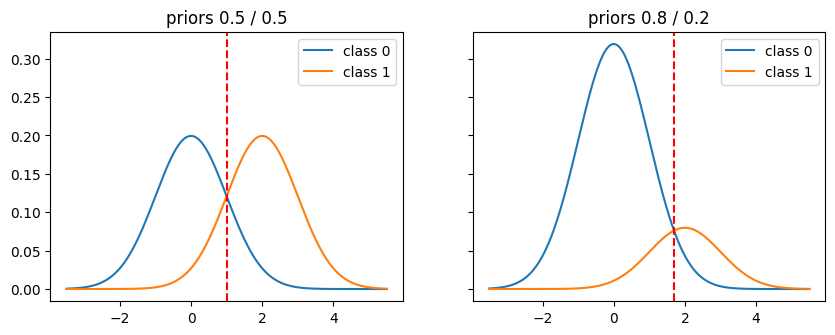

In [68]:
xg = np.linspace(-3.5, 5.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (pi0, pi1) in zip(axes, [(0.5, 0.5), (0.8, 0.2)]):
    f0 = pi0 * stats.norm.pdf(xg, 0, 1)           # prior-weighted densities
    f1 = pi1 * stats.norm.pdf(xg, 2, 1)
    ax.plot(xg, f0, label="class 0")
    ax.plot(xg, f1, label="class 1")
    ax.axvline(1 - np.log(pi1 / pi0) / 2, color="red", ls="--")   # boundary x*
    ax.set_title(f"priors {pi0} / {pi1}")
    ax.legend()
plt.show()

#### Exercise -- LDA in one dimension

Two classes with $X\mid Y=k\sim N(\mu_k,\sigma^2)$, $\sigma^2=1$, $\mu_0=0$, $\mu_1=2$.

1. With equal priors, write down $\delta_0(x)$ and $\delta_1(x)$ and find the decision
   boundary.
2. Classify $x=1.5$.
3. Now take $\pi_0=0.8$, $\pi_1=0.2$. Recompute the boundary and reclassify $x=1.5$.

In [69]:
# Your turn
mu0, mu1, sigma2 = 0, 2, 1

**Solution**

In [70]:
def delta(x, mu, pi):
    return x * mu / sigma2 - mu**2 / (2 * sigma2) + np.log(pi)

def boundary(pi0, pi1):
    return (mu0 + mu1) / 2 - sigma2 / (mu1 - mu0) * np.log(pi1 / pi0)

print(boundary(0.5, 0.5))                                  # (1) x* = 1, the midpoint
print(delta(1.5, mu1, 0.5) > delta(1.5, mu0, 0.5))         # (2) True -> class 1
print(round(np.log(0.8), 3), round(-2 + np.log(0.2), 3))   # (3) delta_0 = -0.223, delta_1 = 2x - 3.609
print(round(boundary(0.8, 0.2), 3))                        #     x* = 1.693
print(delta(1.5, mu1, 0.2) > delta(1.5, mu0, 0.8))         #     False -> class 0

1.0
True
-0.223 -3.609
1.693
False


### A.5 Comparison

Slides: *Logistic regression, LDA and naive Bayes*, *Bayes classifiers with Python*

**In words:** LDA (`balance + student`) catches 81 of 333 defaulters with 23 false alarms;
logistic regression catches 105 with 40 -- similar trade-offs, AUC around 0.95 for both.

In [71]:
# Slide "Bayes classifiers with Python"
X = pd.get_dummies(df[["balance", "student"]], drop_first=True)
lda = LinearDiscriminantAnalysis().fit(X, df.default)
with np.errstate(all="ignore"):     # silences spurious floating-point warnings of some BLAS builds
    print(pd.crosstab(df.default, lda.predict(X)))   # 9644 23 / 252 81
    print(round(roc_auc_score(df.y, lda.predict_proba(X)[:, 1]), 3))   # AUC 0.950
nb = GaussianNB().fit(X, df.default)       # normal f_kj for every feature
print(pd.crosstab(df.default, nb.predict(X)))

col_0      No  Yes
default           
No       9644   23
Yes       252   81
0.95
col_0      No  Yes
default           
No       9618   49
Yes       238   95


## Key Python commands

```python
# Two-way tables and conditional probability
pd.crosstab(df.a, df.b, margins=True)              # counts + totals
pd.crosstab(df.a, df.b, normalize="index")         # rows sum to 1 ("columns", "all")
(d & s).mean() / s.mean()                          # P(A | B) from True/False columns

# Odds and log-odds
odds = p / (1 - p); np.log(odds)                   # probability -> odds -> log-odds
np.exp(eta) / (1 + np.exp(eta))                    # log-odds -> probability

# Logistic regression
g = smf.logit("y ~ x1 + x2", data=df).fit(disp=0)
print(g.summary())                                 # z-tests
np.exp(g.params)                                   # odds ratios
np.exp(g.conf_int())                               # CIs for the odds ratios
g.predict(new)                                     # probabilities (which="linear": log-odds)

# Decisions and evaluation
phat = g.predict(df)
pd.crosstab(df.y, phat > 0.5)                      # confusion matrix, threshold t = 0.5
pd.crosstab(df.y, phat > 0.5, normalize="index")   # sensitivity, specificity
fpr, tpr, thr = roc_curve(df.y, phat)              # ROC curve
roc_auc_score(df.y, phat)                          # AUC
train = df.sample(n=7000, random_state=1)          # training / test split
test = df.drop(train.index)

# Bayes' theorem and Bayes classifiers
joint = prior * lik; joint / joint.sum()           # posterior
LinearDiscriminantAnalysis().fit(X, y)             # LDA
GaussianNB().fit(X, y)                             # naive Bayes
```